# **Performance Comparison of Transformer, LSTM, and XGBoost in USD/IDR Exchange Rate Prediction Based on Historical Data**

## **Objective**

The objective of this study is to compare the forecasting performance of **Transformer**, **Long Short-Term Memory (LSTM)**, and **Extreme Gradient Boosting (XGBoost)** models in predicting the USD/IDR exchange rate using historical data. The study aims to evaluate each model based on its prediction accuracy and ability to capture exchange rate patterns, providing insights into the most effective approach for time series forecasting.

## **Models Used**

Three forecasting models are implemented and compared in this study:

* **Transformer** – A deep learning model based on the self-attention mechanism, capable of capturing long-range dependencies and complex temporal relationships in time series data.

* **Long Short-Term Memory (LSTM)** – A recurrent neural network (RNN) architecture designed to learn long-term dependencies in sequential data, making it widely used for time series forecasting.

* **Extreme Gradient Boosting (XGBoost)** – A gradient boosting algorithm that builds an ensemble of decision trees to model nonlinear relationships and produce accurate predictions from engineered features.


## **Data Source**
The dataset used in this analysis is the USD/IDR Transaction Exchange Rate dataset published by Bank Indonesia (BI). The dataset contains daily official exchange rates for the United States Dollar (USD) against the Indonesian Rupiah (IDR), issued on every working day.

*   **Dataset Link:** https://www.bi.go.id/id/statistik/informasi-kurs/jisdor/Default.aspx

*   **Target Currency:** United States Dollar (USD) to Indonesian Rupiah (IDR)

*   **Time Period:** 1 June 2021 - 30 June 2026


## **Import Library**

In [55]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import statsmodels.api as sm
import matplotlib.dates as mdates
import tensorflow as tf
import torch
import torch.nn as nn
import os

from sklearn.preprocessing import MinMaxScaler
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_absolute_percentage_error, r2_score

from torch.utils.data import DataLoader, TensorDataset

from keras.models import Sequential
from keras.layers import Input, LSTM, Dense, Dropout
from keras.callbacks import EarlyStopping
from keras.optimizers import Adam

from xgboost import XGBRegressor

## **Load Dataset**

In [56]:
df = pd.read_excel('Kurs Jisdor 2016-2026.xlsx')
df.head()

,NO,Tanggal,Kurs
0,1,7/13/2026 12:00:00 AM,18131
1,2,7/10/2026 12:00:00 AM,18069
2,3,7/9/2026 12:00:00 AM,18090
3,4,7/8/2026 12:00:00 AM,18005
4,5,7/7/2026 12:00:00 AM,17988


In [57]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2540 entries, 0 to 2539
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   NO       2540 non-null   int64 
 1   Tanggal  2540 non-null   object
 2   Kurs     2540 non-null   int64 
dtypes: int64(2), object(1)
memory usage: 59.7+ KB


## **Data Preparation**

In [58]:
# Drop unused columns
df.drop(['NO'], axis=1, inplace=True)

In [59]:
# Convert the data type from object to datetime
df['Tanggal'] = pd.to_datetime(df['Tanggal'], format='%m/%d/%Y %I:%M:%S %p')

# Sort by date (ascending)
df = df.sort_values('Tanggal')

In [60]:
# Checking for duplicate data
df[df.duplicated(subset='Tanggal', keep=False)]

,Tanggal,Kurs


In [61]:
# Checking for missing values
df.isna().sum()

Tanggal    0
Kurs       0
dtype: int64

In [62]:
# Checking for missing dates
# Create a date range from the start date to the end date
all_dates = pd.date_range(
    start=df['Tanggal'].min(),
    end=df['Tanggal'].max(),
    freq='D'
)

# Find a date that is not in the data (national holidays, weekends, or technical issues with the recording system)
missing_dates = all_dates.difference(df['Tanggal'])
print(missing_dates)

# Total missing dates
total_missing = len(missing_dates)
print(f'\nTotal missing dates: {total_missing}')

DatetimeIndex(['2016-01-09', '2016-01-10', '2016-01-16', '2016-01-17',
               '2016-01-23', '2016-01-24', '2016-01-30', '2016-01-31',
               '2016-02-06', '2016-02-07',
               ...
               '2026-06-14', '2026-06-16', '2026-06-20', '2026-06-21',
               '2026-06-27', '2026-06-28', '2026-07-04', '2026-07-05',
               '2026-07-11', '2026-07-12'],
              dtype='datetime64[ns]', length=1304, freq=None)

Total missing dates: 1304


In [63]:
# Forward fill missing values (use the previous closing price for non-trading days)
df = (
    df.set_index('Tanggal') # Convert the date column into the index
      .reindex(all_dates)
      .ffill()
)

In [64]:
# Filter data for the 10-year analysis period
df = df.loc['2016-06-01':'2026-06-30']
df.head()

,Kurs
2016-06-01,13671.0
2016-06-02,13695.0
2016-06-03,13612.0
2016-06-04,13612.0
2016-06-05,13612.0


In [65]:
df[['Kurs']].describe().T

,count,mean,std,min,25%,50%,75%,max
Kurs,3682.0,14816.733569,1128.121935,12926.0,14065.0,14546.0,15626.25,18171.0


## **Exploratory Data Analysis (EDA)**

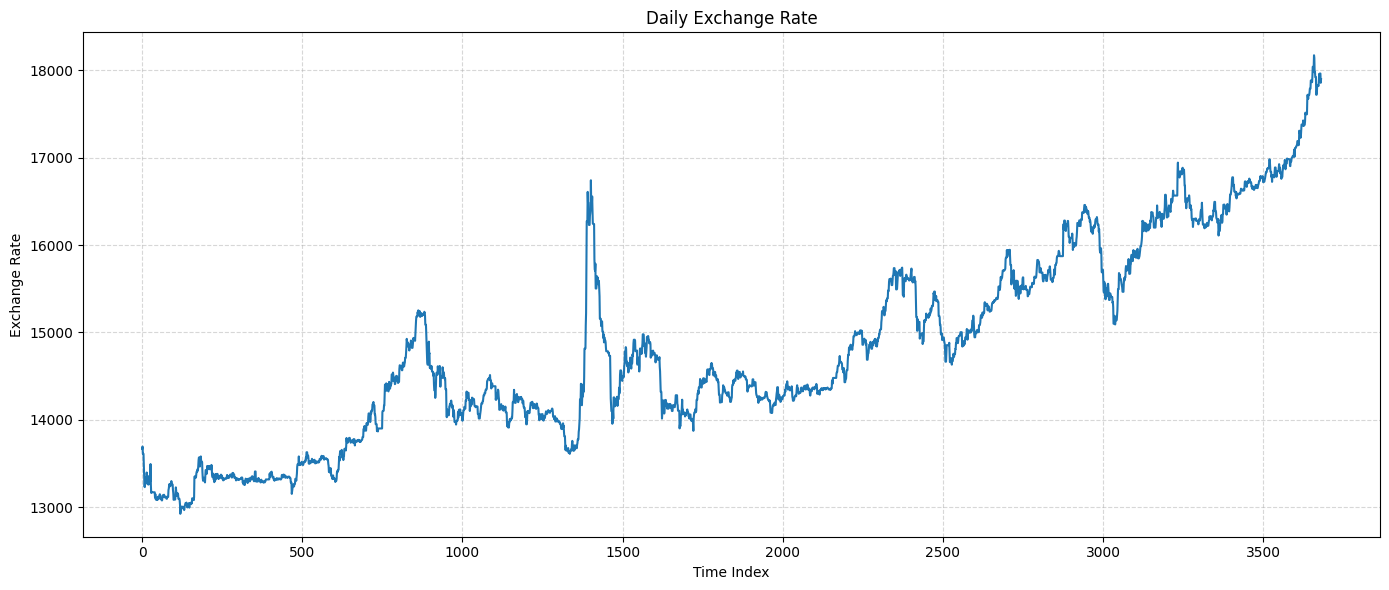

In [66]:
y = df['Kurs']
x = np.arange(y.shape[0])

plt.figure(figsize=(14, 6))
plt.title('Daily Exchange Rate')
plt.plot(x, y)
plt.xlabel('Time Index')
plt.ylabel('Exchange Rate')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

**Key Observations:**

*   **The exchange rate exhibits a clear upward trend over time, increasing from approximately 13,000 to 18,000**, indicating a long-term depreciation of the Indonesian Rupiah against the US Dollar. This trend is influenced by factors such as **global inflation, higher U.S. interest rates, and periods of capital outflows from emerging markets**.

*   **The series shows periods of heightened volatility**, reflecting the exchange rate's sensitivity to global and domestic economic events. Fluctuations are commonly associated with **changes in monetary policy, geopolitical tensions, and shifts in investor sentiment**.

*   **A sharp spike is observed around the middle of the series**, which may correspond to a major economic shock or financial uncertainty, such as the **COVID-19 pandemic**, when global financial markets experienced significant turbulence and investors shifted toward safe-haven assets like the U.S. Dollar.

*   **The exchange rate reaches its highest levels toward the end of the observation period**, which is consistent with the impact of the **U.S. Federal Reserve's prolonged high interest rate policy (2022-2024)**, persistent global inflation, and geopolitical uncertainties that strengthened the U.S. Dollar relative to many emerging market currencies.

*   **The data are non-stationary**, as the exchange rate level changes over time due to evolving macroeconomic conditions, indicating that preprocessing is necessary before applying forecasting models.


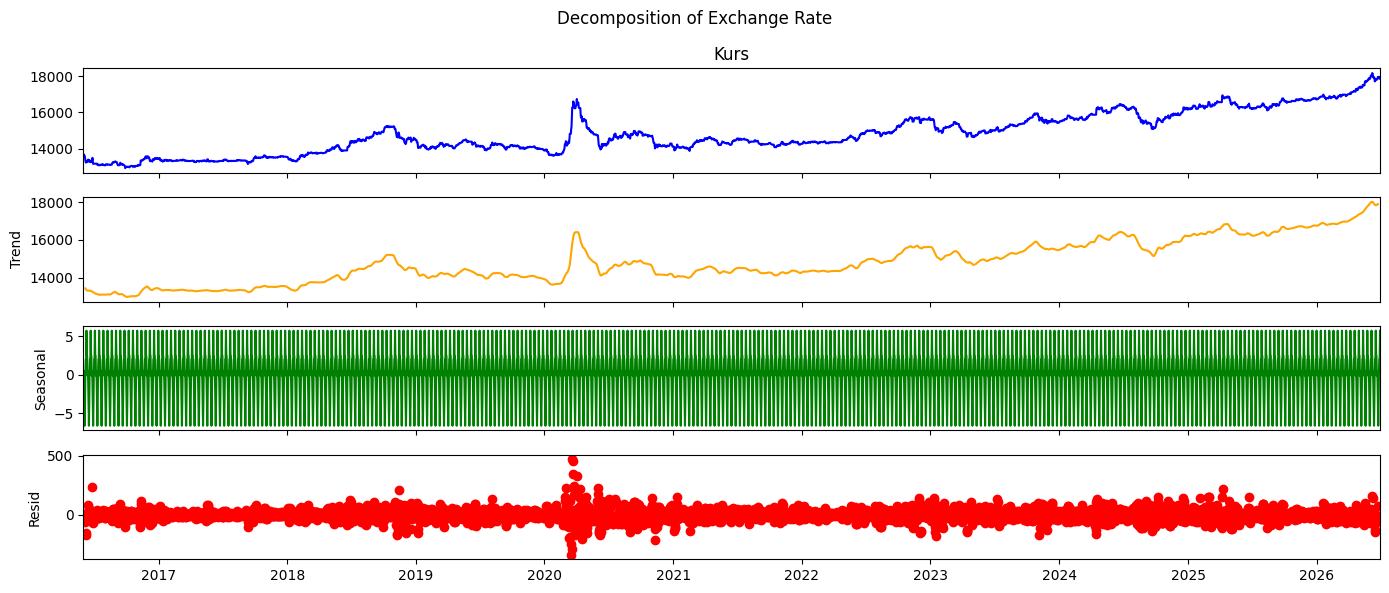

In [67]:
series_to_decompose = df['Kurs']
decomposition = sm.tsa.seasonal_decompose(series_to_decompose, model='additive', period=12)

fig = decomposition.plot()
fig.set_size_inches(14, 6)
fig.suptitle('Decomposition of Exchange Rate')
colors = ['blue', 'orange', 'green', 'red']

for ax, color in zip(fig.axes, colors):
    if ax.lines:
        ax.lines[0].set_color(color)

for ax in fig.axes:
    ax.xaxis.set_major_locator(mdates.YearLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

plt.tight_layout()

**Key Observations:**

*   **Dominant Trend:** The trend component demonstrates a persistent upward movement throughout the study period, indicating that the exchange rate is dominated by long-term structural changes rather than short-term variations. Despite several temporary corrections, the overall trend continues to increase, reflecting the **long-term depreciation of the Indonesian Rupiah against the US Dollar**.

*   **Weak Seasonal Component:** The seasonal component fluctuates periodically around zero with a relatively small magnitude compared to the original exchange rate series. This indicates that seasonal effects are weak and contribute only marginally to exchange rate fluctuations, suggesting that **the exchange rate is not primarily driven by recurring monthly or annual seasonal patterns**.

*   **Irregular Residual Component:** The residual component contains several large deviations, particularly during 2020, indicating the presence of irregular shocks that cannot be explained by the extracted trend and seasonal components. These residual fluctuations imply that **unexpected macroeconomic events and external factors significantly influence exchange rate movements**, highlighting the complexity of modeling exchange rate dynamics.


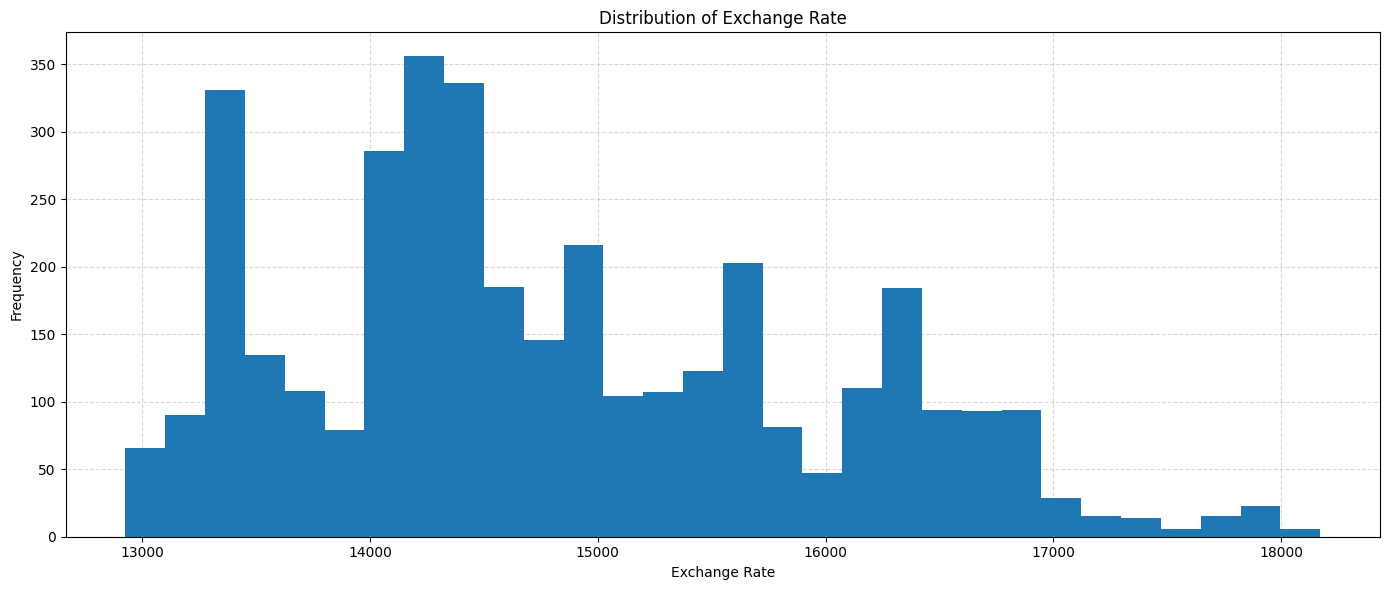

In [68]:
plt.figure(figsize=(14, 6))
plt.hist(df['Kurs'], bins=30, zorder=2)
plt.title('Distribution of Exchange Rate')
plt.xlabel('Exchange Rate')
plt.ylabel('Frequency')
plt.grid(True, linestyle='--', alpha=0.5, zorder=0)
plt.tight_layout()
plt.show()

**Key Observations:**

*   **The exchange rate values range approximately from 12,900 to 18,200**, indicating considerable variation over the observation period.

*   **Most observations are concentrated between 14,000 and 16,500**, showing that exchange rates were most frequently within this range.

*   **The distribution is slightly right-skewed**, with a longer tail toward higher exchange rate values.

*   The histogram **exhibits multiple peaks (multimodal distribution)**, suggesting the presence of different exchange rate regimes or market conditions over time.

*   **The distribution is not normally distributed**, which is typical for financial time series due to changing economic and market conditions.


## **Train/Test Split**

In [69]:
# Split data into train (80%) and test (20%)
train_size = int(len(df) * 0.8)

train = df[['Kurs']][:train_size]
test = df[['Kurs']][train_size:]

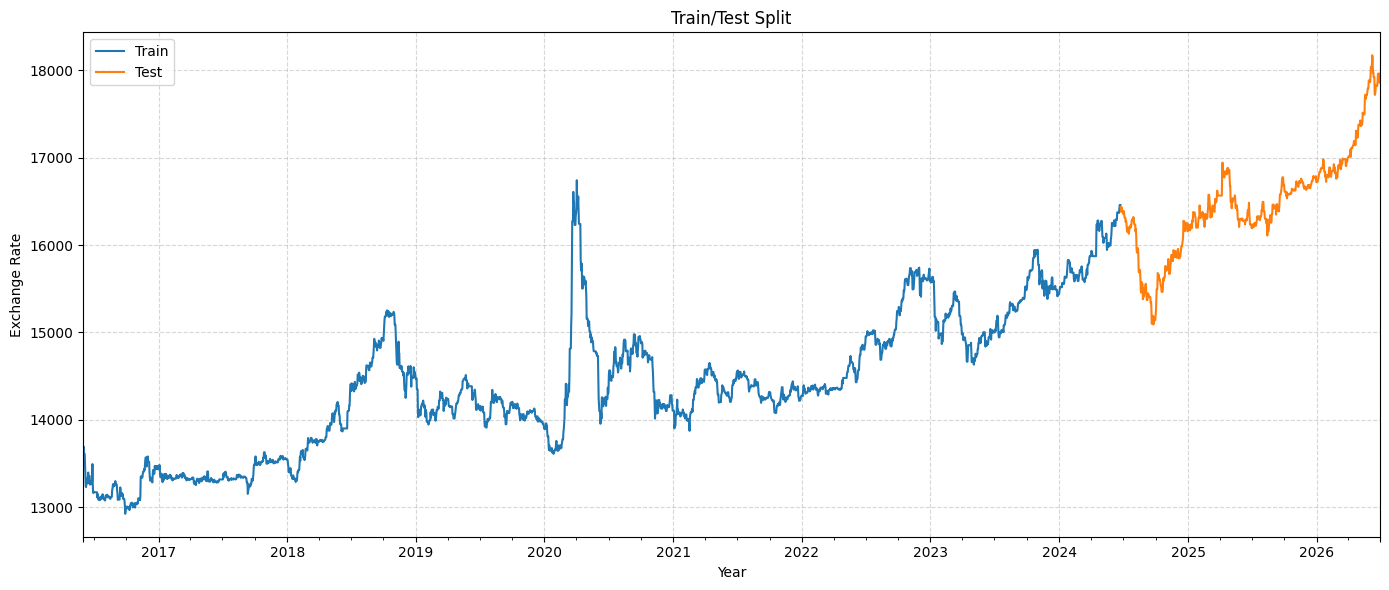

In [70]:
ax = train.plot(figsize=(14, 6))
test.plot(ax=ax)

plt.title('Train/Test Split')
plt.xlabel('Year')
plt.ylabel('Exchange Rate')
plt.legend(['Train', 'Test'])
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

## **Data Normalization**

In [71]:
# Data normalization using Min-Max Scaler
sc = MinMaxScaler(feature_range=(0,1))

train_scaled = sc.fit_transform(train)
test_scaled = sc.transform(test)

## **Choosing the Optimal Window Size**

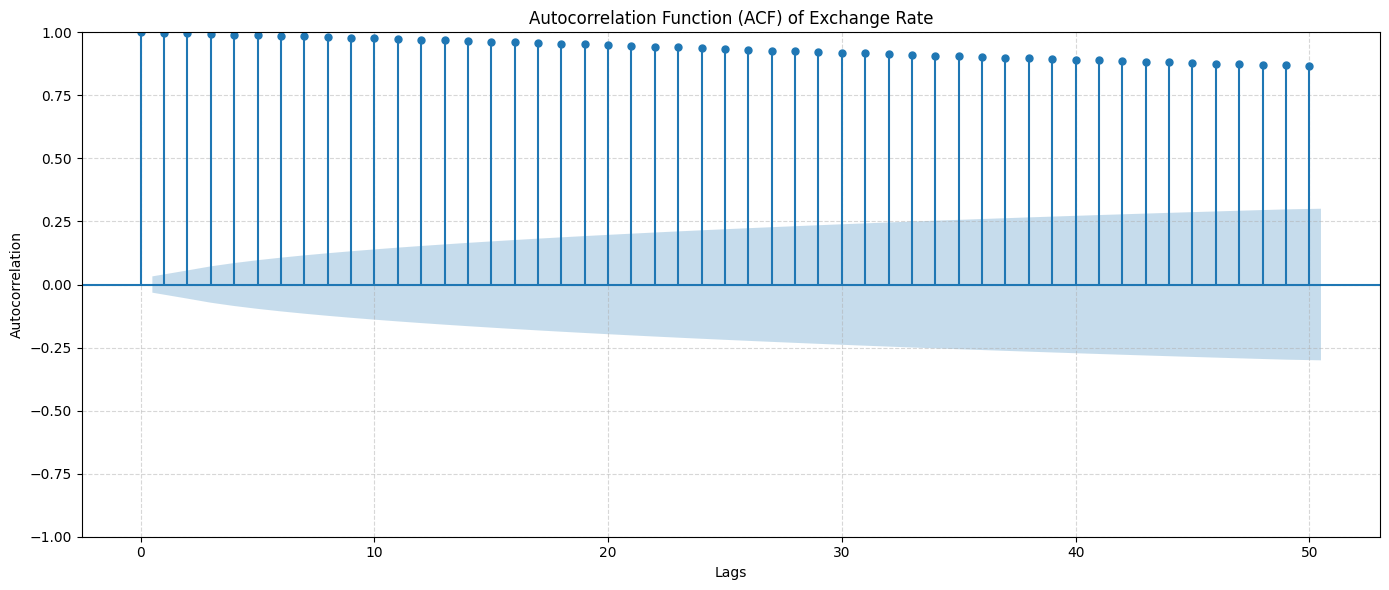

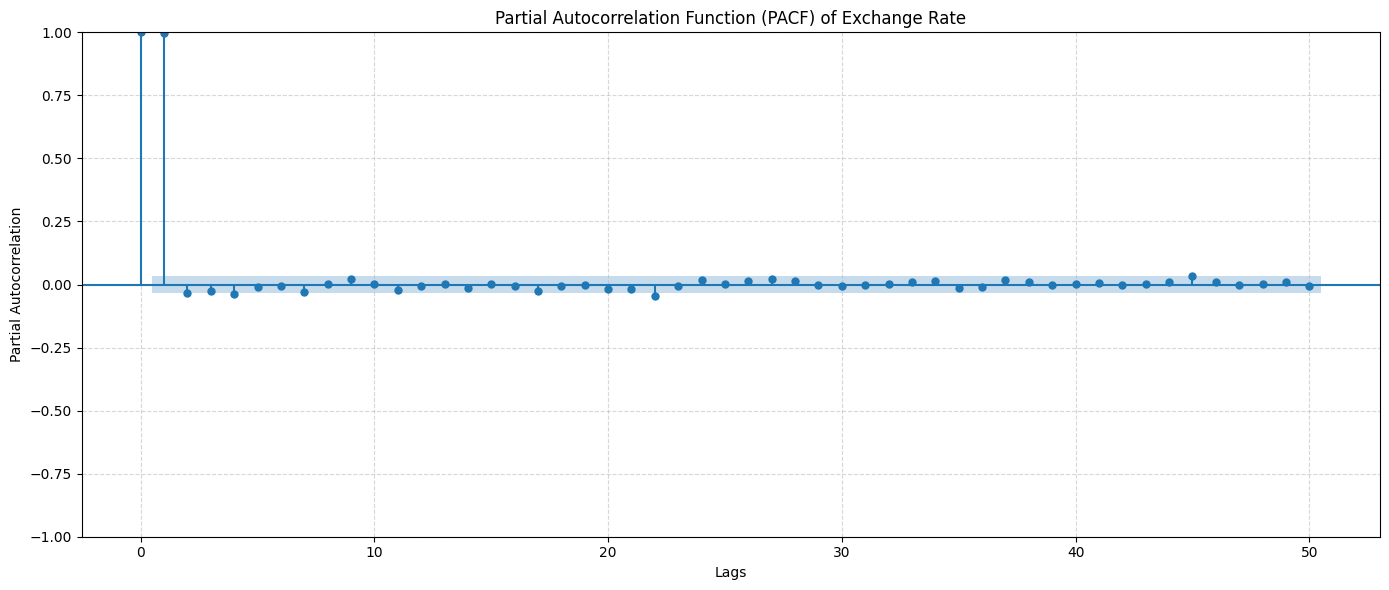

In [72]:
plt.figure(figsize=(14, 6))
plot_acf(df['Kurs'], lags=50, ax=plt.gca(), title='Autocorrelation Function (ACF) of Exchange Rate')
plt.xlabel('Lags')
plt.ylabel('Autocorrelation')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

plt.figure(figsize=(14, 6))
plot_pacf(df['Kurs'], lags=50, ax=plt.gca(), title='Partial Autocorrelation Function (PACF) of Exchange Rate')
plt.xlabel('Lags')
plt.ylabel('Partial Autocorrelation')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()


The ACF and PACF analyses were conducted as preliminary diagnostic tools to examine the temporal dependency structure of the exchange rate data. **The ACF exhibited a slow decay**, indicating strong autocorrelation across multiple lags, while **the PACF showed a significant spike at the first lag**, suggesting that the most substantial direct linear relationship exists with the immediately preceding observation. However, these analyses were used only to characterize the data rather than to determine the optimal window size.

**The final window size was selected based on empirical evaluation using time-series cross-validation**. The experimental results demonstrated that **a window size of 90 achieved the best performance** for the Transformer model, while producing no significant performance degradation for the LSTM and XGBoost models compared to smaller window sizes. Therefore, a window size of 90 was adopted for all models to ensure a fair and consistent comparison under the same input configuration.

## **Sliding Window Method**

In [73]:
# Create input sequences and corresponding target values using a sliding window approach
def create_sliding_window(data, window_size):
    X, y = [], []

    for i in range(len(data) - window_size):
        X.append(data[i:i+window_size])
        y.append(data[i+window_size])

    return np.array(X), np.array(y)

In [74]:
# Predict the next day's exchange rate using the previous 90 days
window_size = 90

X_train, y_train = create_sliding_window(train_scaled, window_size)
X_test, y_test = create_sliding_window(test_scaled, window_size)

print(X_train.shape)
print(X_test.shape)

(2855, 90, 1)
(647, 90, 1)


In [75]:
# Train and test data for Transformer
X_train_tf, y_train_tf = X_train.copy(), y_train.copy()
X_test_tf, y_test_tf = X_test.copy(), y_test.copy()

In [76]:
# Train and test data for LSTM
X_train_lstm, X_test_lstm = X_train.copy(), X_test.copy()
y_train_lstm, y_test_lstm = y_train.copy(), y_test.copy()

In [77]:
# Reshape the input data from (samples, window_size, features) to (samples, window_size × features)
# XGBoost expects a two-dimensional input array
X_train_xgb = X_train.reshape(X_train.shape[0], -1)
X_test_xgb = X_test.reshape(X_test.shape[0], -1)

print('X_train_:', X_train_xgb.shape)
print(X_test_xgb.shape)

X_train_: (2855, 90)
(647, 90)


In [78]:
# Convert the target array from (samples, 1) to (samples,)
# XGBoost expects a one-dimensional target array
y_train_xgb = y_train.ravel()
y_test_xgb = y_test.ravel()

## **Data Modeling (Transformer)**

In [79]:
has_mps = torch.backends.mps.is_built()
device = "mps" if has_mps else "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {device}")

Using device: mps


In [80]:
X_train_tf = torch.tensor(X_train_tf, dtype=torch.float32)
y_train_tf = torch.tensor(y_train_tf, dtype=torch.float32)
X_test_tf = torch.tensor(X_test_tf, dtype=torch.float32)
y_test_tf = torch.tensor(y_test_tf, dtype=torch.float32)

BATCH_SIZE = 32

train_dataset_tf = TensorDataset(X_train_tf, y_train_tf)
train_loader_tf = DataLoader(train_dataset_tf, batch_size=BATCH_SIZE, shuffle=False)

test_dataset_tf = TensorDataset(X_test_tf, y_test_tf)
test_loader_tf = DataLoader(test_dataset_tf, batch_size=BATCH_SIZE, shuffle=False)

print('X_train_tf:', X_train_tf.shape)
print('X_test_tf :', X_test_tf.shape)

X_train_tf: torch.Size([2855, 90, 1])
X_test_tf : torch.Size([647, 90, 1])


In [81]:
# Positional Encoding for Transformer
class PositionalEncoding(nn.Module):
    def __init__(self, d_model, dropout=0.1, max_len=5000):
        super(PositionalEncoding, self).__init__()
        self.dropout = nn.Dropout(p=dropout)

        pe = torch.zeros(max_len, d_model)
        position = torch.arange(0, max_len, dtype=torch.float).unsqueeze(1)
        div_term = torch.exp(torch.arange(0, d_model, 2).float() * (-np.log(10000.0) / d_model))
        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)
        pe = pe.unsqueeze(0).transpose(0, 1)
        self.register_buffer('pe', pe)

    def forward(self, x):
        x = x + self.pe[:x.size(1)].transpose(0, 1)
        return self.dropout(x)

In [82]:
# Model definition using Transformer
class TransformerModel(nn.Module):
    def __init__(self, input_dim=1, d_model=64, nhead=4, num_layers=2,
                 dim_feedforward=128, dropout=0.1):
        super(TransformerModel, self).__init__()

        self.encoder = nn.Linear(input_dim, d_model)
        self.pos_encoder = PositionalEncoding(d_model, dropout)
        encoder_layers = nn.TransformerEncoderLayer(d_model, nhead, dim_feedforward=dim_feedforward, dropout=dropout, batch_first=True)
        self.transformer_encoder = nn.TransformerEncoder(encoder_layers, num_layers)
        self.decoder = nn.Linear(d_model, 1)

    def forward(self, x):
        x = self.encoder(x)
        x = self.pos_encoder(x)
        x = self.transformer_encoder(x)
        x = self.decoder(x[:, -1, :])
        return x

In [83]:
os.makedirs('weight', exist_ok=True)

model_tf = TransformerModel(
    input_dim=X_train_tf.shape[2], d_model=64, nhead=4, num_layers=2, dropout=0.1
).to(device)

criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model_tf.parameters(), lr=0.001)

epochs = 100
early_stop_patience = 10
early_stop_count = 0
min_val_loss = float('inf')

train_loss_list = []
val_loss_list = []

for epoch in range(epochs):
    model_tf.train()
    train_losses = []
    for x_batch, y_batch in train_loader_tf:
        x_batch, y_batch = x_batch.to(device), y_batch.to(device)

        optimizer.zero_grad()
        outputs = model_tf(x_batch)
        loss = criterion(outputs, y_batch)
        loss.backward()
        optimizer.step()

        train_losses.append(loss.item())

    epoch_train_loss = np.mean(train_losses)
    train_loss_list.append(epoch_train_loss)

    # Validation
    model_tf.eval()
    val_losses = []
    with torch.no_grad():
        for x_batch, y_batch in test_loader_tf:
            x_batch, y_batch = x_batch.to(device), y_batch.to(device)
            outputs = model_tf(x_batch)
            val_loss = criterion(outputs, y_batch)
            val_losses.append(val_loss.item())

    epoch_val_loss = np.mean(val_losses)
    val_loss_list.append(epoch_val_loss)

    if epoch_val_loss < min_val_loss:
        min_val_loss = epoch_val_loss
        early_stop_count = 0
        torch.save(model_tf.state_dict(), 'weight/best_transformer.pth')
    else:
        early_stop_count += 1

    if (epoch + 1) % 5 == 0 or epoch == 0:
        print(f"Epoch {epoch + 1}/{epochs}, Train Loss: {epoch_train_loss:.6f}, Val Loss: {epoch_val_loss:.6f}")

    if early_stop_count >= early_stop_patience:
        print(f"Early stopping at epoch {epoch + 1}")
        break

Epoch 1/100, Train Loss: 0.047900, Val Loss: 0.027799
Epoch 5/100, Train Loss: 0.043825, Val Loss: 0.006711
Epoch 10/100, Train Loss: 0.007626, Val Loss: 0.005326
Epoch 15/100, Train Loss: 0.005859, Val Loss: 0.006171
Early stopping at epoch 16


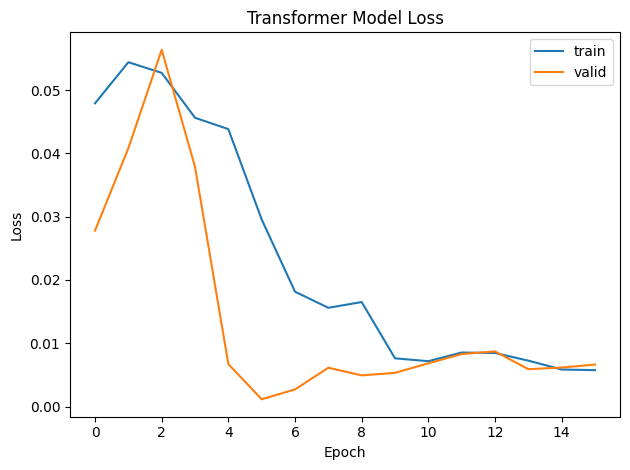

In [84]:
plt.plot(train_loss_list)
plt.plot(val_loss_list)

plt.title('Transformer Model Loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend(['train', 'valid'])
plt.tight_layout()
plt.show()

In [85]:
# Load the best checkpoint (lowest validation loss) before evaluating
model_tf.load_state_dict(torch.load('weight/best_transformer.pth'))
model_tf.eval()

y_pred_tf = []
with torch.no_grad():
    for x_batch, y_batch in test_loader_tf:
        x_batch = x_batch.to(device)
        outputs = model_tf(x_batch)
        y_pred_tf.extend(outputs.squeeze(-1).cpu().tolist())

In [86]:
y_test_tf = sc.inverse_transform(y_test_tf.numpy().reshape(-1, 1))
y_test_tf[:10]

array([[15100.],
       [15191.],
       [15186.],
       [15092.],
       [15171.],
       [15138.],
       [15138.],
       [15138.],
       [15144.],
       [15204.]], dtype=float32)

In [87]:
y_pred_tf = sc.inverse_transform(np.array(y_pred_tf).reshape(-1, 1))
y_pred_tf[:10]

array([[15428.1821022 ],
       [15416.7633996 ],
       [15443.05602199],
       [15435.32174742],
       [15395.18392539],
       [15421.92610121],
       [15403.8589195 ],
       [15397.20725691],
       [15388.45131135],
       [15378.72372097]])

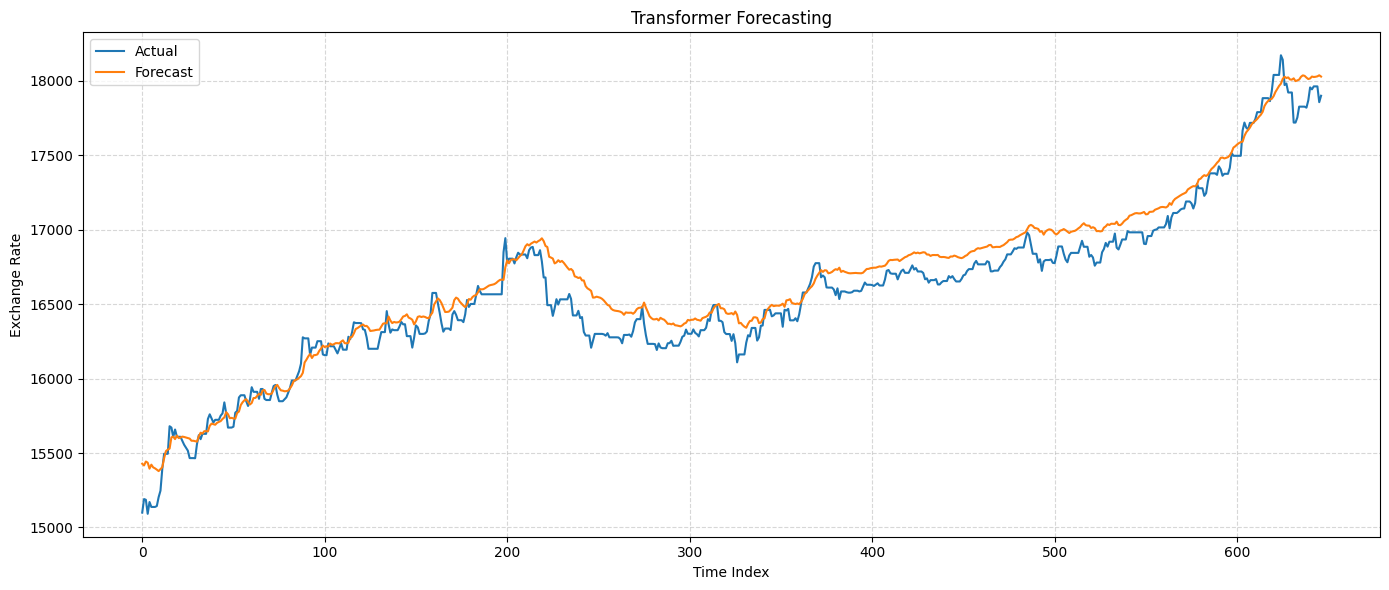

In [88]:
plt.figure(figsize=(14, 6))
plt.plot(y_test_tf, label='Actual')
plt.plot(y_pred_tf, label='Forecast')
plt.title('Transformer Forecasting')
plt.xlabel('Time Index')
plt.ylabel('Exchange Rate')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

In [89]:
tf_mae = mean_absolute_error(y_test_tf, y_pred_tf)
tf_rmse = np.sqrt(mean_squared_error(y_test_tf, y_pred_tf))
tf_mape = mean_absolute_percentage_error(y_test_tf, y_pred_tf)
tf_r2 = r2_score(y_test_tf, y_pred_tf)

print(f'Mean Absolute Error (MAE): {tf_mae:.4f}')
print(f'Root Mean Squared Error (RMSE): {tf_rmse:.4f}')
print(f'Mean Absolute Percentage Error (MAPE): {tf_mape*100:.4f}%')
print(f'R² Score: {tf_r2:.4f}')

Mean Absolute Error (MAE): 108.8187
Root Mean Squared Error (RMSE): 130.8974
Mean Absolute Percentage Error (MAPE): 0.6575%
R² Score: 0.9445


## **Data Modeling (LSTM)**

In [90]:
model_lstm = Sequential([
     Input(shape=(X_train_lstm.shape[1], X_train_lstm.shape[2])),
     LSTM(64, return_sequences=True),
     Dropout(0.1),
     LSTM(64),
     Dropout(0.1),
     Dense(1, activation='linear')
])

In [91]:
model_lstm.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_2 (LSTM)                   │ (None, 90, 64)         │        16,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 90, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_3 (LSTM)                   │ (None, 64)             │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 49,985 (195.25 KB)

 Trainable params: 49,985 (195.25 KB)

 Non-trainable params: 0 (0.00 B)

In [92]:
model_lstm.compile(optimizer=Adam(learning_rate=0.001), loss = 'mse')

In [93]:
early_stopping = EarlyStopping(
    monitor='val_loss', patience=10, restore_best_weights=True
)

In [94]:
history = model_lstm.fit(
    X_train_lstm, y_train_lstm, validation_data=(X_test_lstm, y_test_lstm),
    epochs=100, batch_size=32, callbacks=[early_stopping]
)

Epoch 1/100
90/90 ━━━━━━━━━━━━━━━━━━━━ 3s 21ms/step - loss: 0.0324 - val_loss: 0.0013
Epoch 2/100
90/90 ━━━━━━━━━━━━━━━━━━━━ 2s 21ms/step - loss: 0.0021 - val_loss: 6.5715e-04
Epoch 3/100
90/90 ━━━━━━━━━━━━━━━━━━━━ 2s 23ms/step - loss: 0.0016 - val_loss: 8.1280e-04
Epoch 4/100
90/90 ━━━━━━━━━━━━━━━━━━━━ 2s 20ms/step - loss: 0.0017 - val_loss: 0.0031
Epoch 5/100
90/90 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step - loss: 0.0017 - val_loss: 0.0020
Epoch 6/100
90/90 ━━━━━━━━━━━━━━━━━━━━ 2s 20ms/step - loss: 0.0013 - val_loss: 0.0013
Epoch 7/100
90/90 ━━━━━━━━━━━━━━━━━━━━ 2s 22ms/step - loss: 0.0012 - val_loss: 0.0029
Epoch 8/100
90/90 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step - loss: 0.0012 - val_loss: 0.0026
Epoch 9/100
90/90 ━━━━━━━━━━━━━━━━━━━━ 2s 20ms/step - loss: 0.0012 - val_loss: 4.8941e-04
Epoch 10/100
90/90 ━━━━━━━━━━━━━━━━━━━━ 2s 24ms/step - loss: 9.9850e-04 - val_loss: 9.9332e-04
Epoch 11/100
90/90 ━━━━━━━━━━━━━━━━━━━━ 2s 21ms/step - loss: 0.0010 - val_loss: 0.0014
Epoch 12/100
90/90 ━━━━━━━━━━━━━

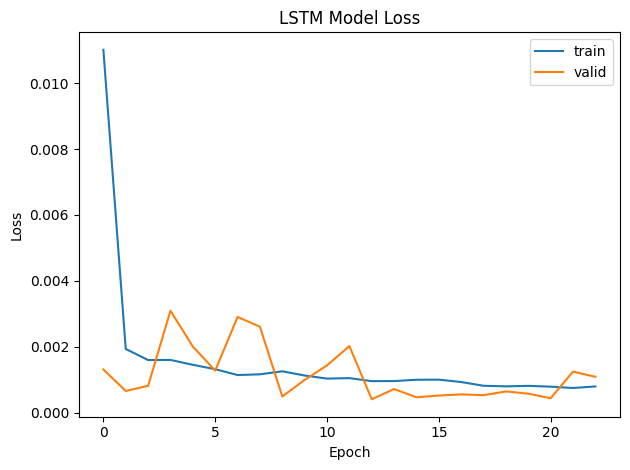

In [95]:
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])

plt.title('LSTM Model Loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend(['train', 'valid'])
plt.tight_layout()
plt.show()

In [96]:
y_pred_lstm = model_lstm.predict(X_test_lstm)

21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step


In [97]:
y_test_lstm = sc.inverse_transform(y_test_lstm.reshape(-1,1))
y_test_lstm[:10]

array([[15100.],
       [15191.],
       [15186.],
       [15092.],
       [15171.],
       [15138.],
       [15138.],
       [15138.],
       [15144.],
       [15204.]])

In [98]:
y_pred_lstm = sc.inverse_transform(y_pred_lstm)
y_pred_lstm[:10]

array([[15307.419],
       [15249.4  ],
       [15214.085],
       [15196.048],
       [15177.66 ],
       [15173.747],
       [15173.904],
       [15176.913],
       [15181.332],
       [15186.957]], dtype=float32)

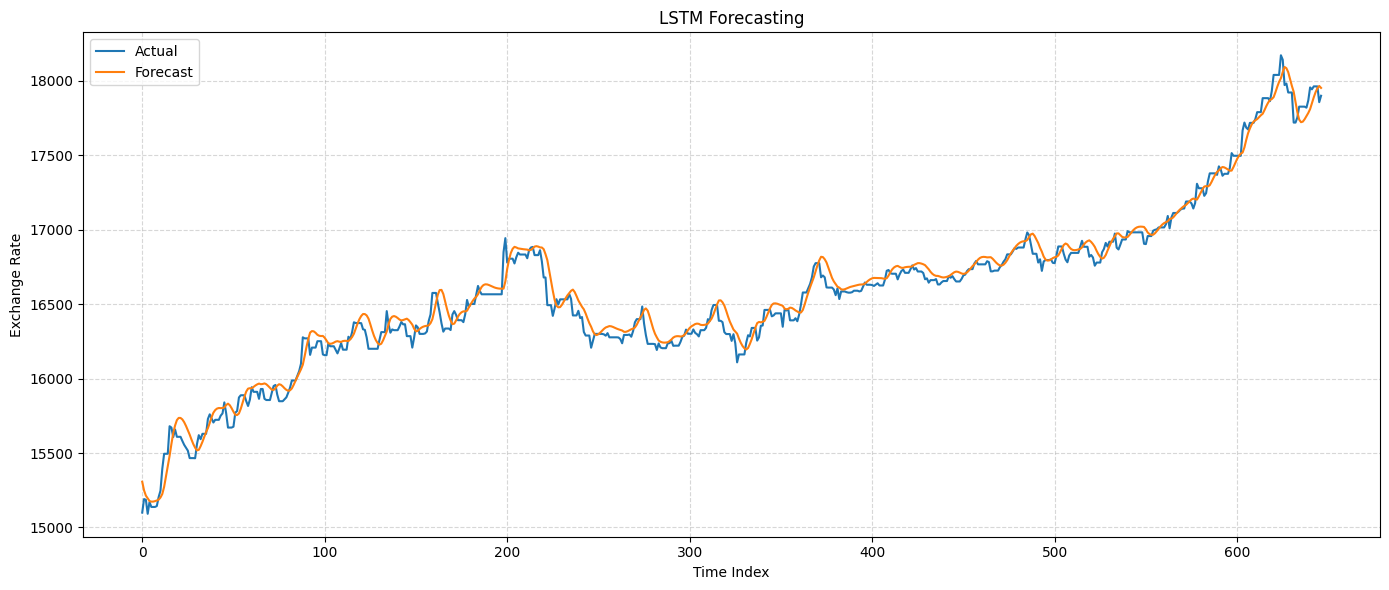

In [99]:
plt.figure(figsize=(14, 6))
plt.plot(y_test_lstm, label='Actual')
plt.plot(y_pred_lstm, label='Forecast')
plt.title('LSTM Forecasting')
plt.xlabel('Time Index')
plt.ylabel('Exchange Rate')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

In [100]:
lstm_mae = mean_absolute_error(y_test_lstm, y_pred_lstm)
lstm_rmse = np.sqrt(mean_squared_error(y_test_lstm, y_pred_lstm))
lstm_mape = mean_absolute_percentage_error(y_test_lstm, y_pred_lstm)
lstm_r2 = r2_score(y_test_lstm, y_pred_lstm)

print(f'Mean Absolute Error (MAE): {lstm_mae:.4f}')
print(f'Root Mean Squared Error (RMSE): {lstm_rmse:.4f}')
print(f'Mean Absolute Percentage Error (MAPE): {lstm_mape*100:.4f}%')
print(f'R² Score: {lstm_r2:.4f}')

Mean Absolute Error (MAE): 59.2327
Root Mean Squared Error (RMSE): 76.8076
Mean Absolute Percentage Error (MAPE): 0.3593%
R² Score: 0.9809


## **Data Modeling (XGBoost)**

In [101]:
model_xgb = XGBRegressor(
    n_estimators=500, max_depth=6, learning_rate=0.05,
    subsample=0.8, colsample_bytree=0.8, objective='reg:squarederror',
    early_stopping_rounds=10
)

In [102]:
model_xgb.fit(
    X_train_xgb, y_train_xgb,
    eval_set=[(X_test_xgb, y_test_xgb)],
    verbose=False
)

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=0.8, device=None, early_stopping_rounds=10,
             enable_categorical=False, eval_metric=None, feature_types=None,
             gamma=None, grow_policy=None, importance_type=None,
             interaction_constraints=None, learning_rate=0.05, max_bin=None,
             max_cat_threshold=None, max_cat_to_onehot=None,
             max_delta_step=None, max_depth=6, max_leaves=None,
             min_child_weight=None, missing=nan, monotone_constraints=None,
             multi_strategy=None, n_estimators=500, n_jobs=None,
             num_parallel_tree=None, random_state=None, ...)

In [103]:
y_pred_xgb = model_xgb.predict(X_test_xgb)

In [104]:
y_test_xgb = sc.inverse_transform(y_test_xgb.reshape(-1, 1))
y_test_xgb[:10]

array([[15100.],
       [15191.],
       [15186.],
       [15092.],
       [15171.],
       [15138.],
       [15138.],
       [15138.],
       [15144.],
       [15204.]])

In [105]:
y_pred_xgb = sc.inverse_transform(y_pred_xgb.reshape(-1, 1))
y_pred_xgb[:10]

array([[14975.862],
       [14948.98 ],
       [15018.352],
       [15025.637],
       [14972.247],
       [15024.096],
       [14997.327],
       [14991.222],
       [14990.814],
       [15019.351]], dtype=float32)

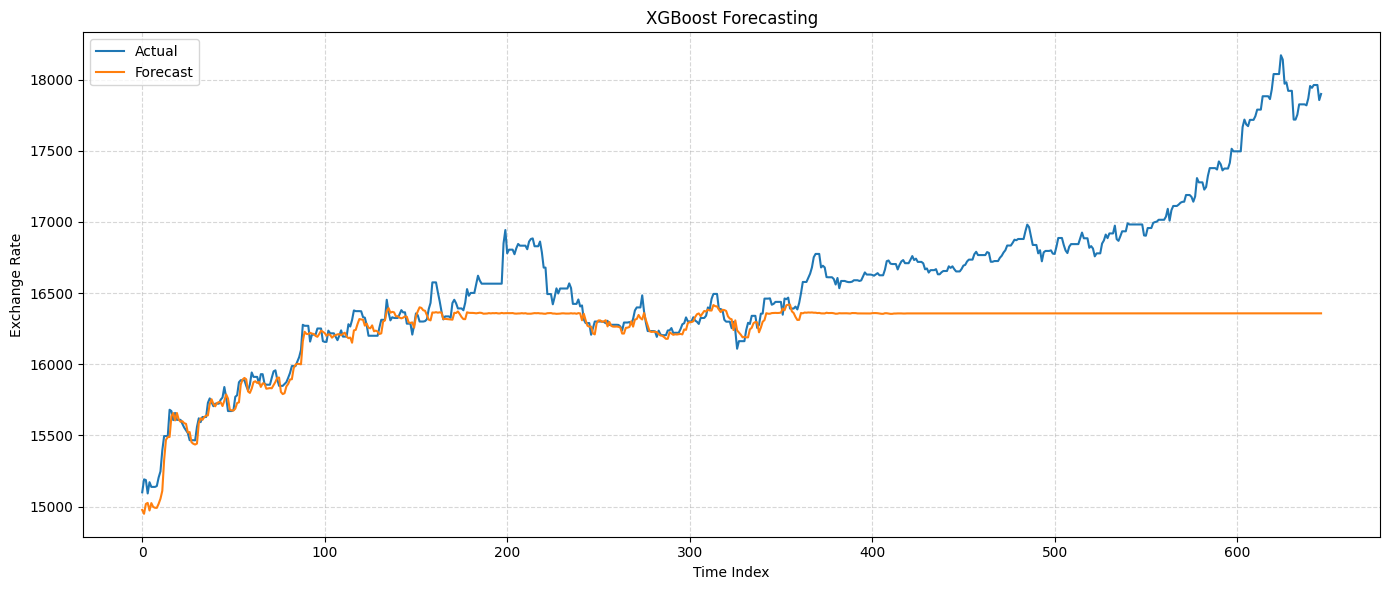

In [106]:
plt.figure(figsize=(14, 6))
plt.plot(y_test_xgb, label='Actual')
plt.plot(y_pred_xgb, label='Forecast')
plt.title('XGBoost Forecasting')
plt.xlabel('Time Index')
plt.ylabel('Exchange Rate')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

In [107]:
xgboost_mae = mean_absolute_error(y_test_xgb, y_pred_xgb)
xgboost_rmse = np.sqrt(mean_squared_error(y_test_xgb, y_pred_xgb))
xgboost_mape = mean_absolute_percentage_error(y_test_xgb, y_pred_xgb)
xgboost_r2 = r2_score(y_test_xgb, y_pred_xgb)

print(f'Mean Absolute Error (MAE): {xgboost_mae:.4f}')
print(f'Root Mean Squared Error (RMSE): {xgboost_rmse:.4f}')
print(f'Mean Absolute Percentage Error (MAPE): {xgboost_mape*100:.4f}%')
print(f'R² Score: {xgboost_r2:.4f}')

Mean Absolute Error (MAE): 339.9058
Root Mean Squared Error (RMSE): 530.3518
Mean Absolute Percentage Error (MAPE): 1.9832%
R² Score: 0.0894


## **Model Evaluation**

In [108]:
evaluation_df = pd.DataFrame({
    'Model': ['Transformer', 'LSTM', 'XGBoost'],
    'MAE': [tf_mae, lstm_mae, xgboost_mae],
    'RMSE': [tf_rmse, lstm_rmse, xgboost_rmse],
    'MAPE (%)': [tf_mape * 100, lstm_mape * 100, xgboost_mape * 100],
    'R²': [tf_r2, lstm_r2, xgboost_r2]
})

evaluation_df = evaluation_df.round({
    'MAE': 4,
    'RMSE': 4,
    'MAPE (%)': 4,
    'R²': 4
})

evaluation_df

,Model,MAE,RMSE,MAPE (%),R²
0,Transformer,108.8187,130.8974,0.6575,0.9445
1,LSTM,59.2327,76.8076,0.3593,0.9809
2,XGBoost,339.9058,530.3518,1.9832,0.0894
